In [31]:
import os
import sys
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import time
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.helper_functions import load_outlier_data
from utils.constants import Configs
from utils.plotting import plot_dimesionality_reduction_outliers

# Define the target movement for anomaly detection
TARGET_MOVEMENT = 'Place'

In [32]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if os.path.exists(cache_path):
    print(f"Loading processed data from {cache_path}")
    df = pd.read_csv(cache_path)
else:
    print(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

Loading processed data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/data/processed/filtered_data_bimanual.csv


In [33]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")
    
# Load the known outliers from the csv
outliers_left_csv, total_known_outliers_left = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, total_known_outliers_right = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)


outliers_bimanual = pd.concat([outliers_left_csv, outliers_right_csv])
total_known_outliers = len(outliers_bimanual)

# O drop_duplicates garante que se o sub 13 falhou com as duas mãos, conta como 1 erro
outliers_bimanual = outliers_bimanual.drop_duplicates(subset=['sub', 'repID']).copy()
total_known_outliers = len(outliers_bimanual)

print(f"Total de OUTLIERS BIMANUAIS (Ground Truth): {total_known_outliers}")


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
Total de OUTLIERS BIMANUAIS (Ground Truth): 24


### Discard sub 13.
Aparently his movements were not good at all. The existance of those movements might influence the detection of other outliers 

In [34]:
# Discard from dataset
df.drop(df[df['sub']== 13].index, inplace=True)

# Discard from outliers csv
outliers_bimanual.drop(outliers_bimanual[outliers_bimanual['sub'] == 13].index, inplace=True)
outliers_bimanual[outliers_bimanual['sub'] == 13]

,sub,repID


In [35]:
# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = [
    'xs_L', 'ys_L', 'zs_L', 'xe_L', 'ye_L', 'ze_L', 'xw_L', 'yw_L', 'zw_L', # Braço Esquerdo
    'xs_R', 'ys_R', 'zs_R', 'xe_R', 'ye_R', 'ze_R', 'xw_R', 'yw_R', 'zw_R'  # Braço Direito
]
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, 18)

Processing time series: 100%|██████████| 360/360 [00:00<00:00, 6679.45it/s]

Shape of first series: (121, 18)
Shape of formatted series: (360, 2126, 18)


In [36]:
# =========================================================================
# A BASE DE CÁLCULO 
# =========================================================================

# Extrair os metadados diretamente da fonte da verdade
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

# --- Parâmetros Dinâmicos (Limites de Lixo) ---
total_trials = len(results_temp_base)
known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100


if total_trials != X_movement.shape[0]:
    print(f"⚠️ ERRO CRÍTICO: Metadados ({total_trials}) não batem com Matriz ({X_movement.shape[0]})!")
else:
    print(f"✅ Sincronização Perfeita! Linhas na Matriz: {X_movement.shape[0]} | Linhas nos Metadados: {total_trials}")

✅ Sincronização Perfeita! Linhas na Matriz: 360 | Linhas nos Metadados: 360


## PCA

In [37]:
print(f"\n--- A preparar dados para PCA Bimanual ({TARGET_MOVEMENT}) ---")

# Extrair TODAS as 18 coordenadas
X_all = X_movement.copy() 
n_samples, n_timepoints, n_dims = X_all.shape  # n_dims será automaticamente 18

# LIMPEZA DE NaNs (Forward Fill - Obrigatório para PCA)
for i in range(n_samples):
    for j in range(n_dims):
        s = pd.Series(X_all[i, :, j])
        X_all[i, :, j] = s.ffill().bfill().values

# Concatenação (Esmagar de 3D para 2D)
# Passamos para uma matriz plana de (n_samples, n_timepoints * 18)
X_flat = np.transpose(X_all, (0, 2, 1)).reshape(n_samples, n_timepoints * n_dims)


--- A preparar dados para PCA Bimanual (Place) ---


In [38]:
print("\n--- Iniciando Grid Search Dinâmico (PCA + LOF Bimanuais) ---")

df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)

total_trials = len(results_temp_base)
known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100

# PCA grid search parameters
min_n_components = 3
max_n_components = 20

# LOF grid search parameters
min_contam = 0.01
max_contam = known_outlier_rate + 0.10         
contamination_range = [round(c, 3) for c in np.linspace(min_contam, max_contam, 15)]
n_neighbors_options = [3, 5, 7, 10, 15, 20]

results_log = []

for n_comp in range(min_n_components, max_n_components + 1):
    pca_start_time = time.perf_counter()
    pca = PCA(n_components=n_comp)
    pca_scores_reduced = pca.fit_transform(X_flat)
    pca_end_time = time.perf_counter()

    for n_neigh in n_neighbors_options:
        for contam in contamination_range:
            lof_start_time = time.perf_counter()

            # TREINO DO LOF nos scores bimanuais reduzidos
            model = LocalOutlierFactor(n_neighbors=n_neigh, contamination=contam, metric='minkowski')
            labels = model.fit_predict(pca_scores_reduced)
            lof_end_time = time.perf_counter()
        
            # --- CÁLCULO DE MÉTRICAS ---
            results_temp = results_temp_base.copy()
            results_temp['label'] = labels
            
            real_outliers_info = results_temp[results_temp['label'] == -1]
            identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])
            
            matched_outliers = pd.merge(identified_unique, outliers_bimanual, on=['sub', 'repID'], how='inner')
            missing_outliers = pd.merge(outliers_bimanual, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
            missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']
            
            TP = len(matched_outliers)
            FP = len(identified_unique) - TP
            FN = len(missing_outliers)
            
            if (TP + FP) > 0:
                precision = (TP / (TP + FP)) * 100
                recall = (TP / total_known_outliers) * 100
                f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
                f2_score = (5 * precision * recall) / (4 * precision + recall) if (precision + recall) > 0 else 0
            else:
                precision, recall, f1_score, f2_score = 0.0, 0.0, 0.0, 0.0
                
            percentagem_lixo = (len(identified_unique) / total_trials) * 100
                
            results_log.append({
                'n_neighbors': n_neigh,
                'n_components': n_comp,
                'contamination': contam,
                'total_time': (pca_end_time - pca_start_time) + (lof_end_time - lof_start_time),
                'Recall': recall,
                'Precision': precision,
                'F1-Score': f1_score,
                'F2-Score': f2_score,
                'TP': TP,
                'FP': FP,
                'FN': FN,
                'Percentagem Lixo': percentagem_lixo
            })


--- Iniciando Grid Search Dinâmico (PCA + LOF Bimanuais) ---


In [39]:
# --- SELEÇÃO DO MELHOR MODELO ---
results_df = pd.DataFrame(results_log)
limite_lixo = percentagem_conhecida + 5.0 
acceptable_models = results_df[results_df['Percentagem Lixo'] <= limite_lixo]

if acceptable_models.empty:
    acceptable_models = results_df

best_results = acceptable_models.sort_values(by=['F2-Score', 'Percentagem Lixo'], ascending=[False, True])
best_params = best_results.iloc[0]

percentagem_lixo = best_params['Percentagem Lixo']
retencao = 100 - best_params['Percentagem Lixo']
print(f"--- Grid Search (PCA + LOF): ---")
print(f"PCA Components: {best_params['n_components']}")
print(f"LOF Neighbors: {best_params['n_neighbors']} | Contamination: {best_params['contamination']}")
print(f"Precision: {best_params['Precision']:.2f}% | Recall: {best_params['Recall']:.2f}%")
print(f"F1-Score: {best_params['F1-Score']:.2f}% | F2-Score: {best_params['F2-Score']:.2f}%")
print(f"Retencao: {retencao:.2f}% | Lixo: {percentagem_lixo:.2f}%")
print(f"TP: {best_params['TP']} | FP: {best_params['FP']} | FN: {best_params['FN']}")
print(f"Total Time: {best_params['total_time']:.4f} segundos")

--- Grid Search (PCA + LOF): ---
PCA Components: 5.0
LOF Neighbors: 20.0 | Contamination: 0.144
Precision: 43.75% | Recall: 58.33%
F1-Score: 50.00% | F2-Score: 54.69%
Retencao: 91.11% | Lixo: 8.89%
TP: 14.0 | FP: 18.0 | FN: 8.0
Total Time: 0.4791 segundos


In [40]:
print("\n--- A EXTRAIR AS TRAJETÓRIAS ANÓMALAS ORIGINAIS ---")

best_n_comp = int(best_params['n_components'])
best_n_neigh = int(best_params['n_neighbors'])
best_contam = best_params['contamination']

# Re-treinar a pipeline final com os parâmetros de coordenação bimanual vencedores
pca_final = PCA(n_components=best_n_comp)
pca_scores_final = pca_final.fit_transform(X_flat)

model_final = LocalOutlierFactor(n_neighbors=best_n_neigh, contamination=best_contam, metric='minkowski')
final_labels = model_final.fit_predict(pca_scores_final)

outlier_indices = np.where(final_labels == -1)[0]
inlier_indices = np.where(final_labels == 1)[0]

n_outliers = len(outlier_indices)

# Cortar o array bimanual original usando os índices anómalos
X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(f"Total de Repetições Originais: {len(X_movement)}")
print(f"Outliers Detetados de Coordenação: {n_outliers}")
print(f"Percentagem de lixo bimanual: {n_outliers / len(X_movement) * 100:.2f}%")


--- A EXTRAIR AS TRAJETÓRIAS ANÓMALAS ORIGINAIS ---
Total de Repetições Originais: 360
Outliers Detetados de Coordenação: 52
Percentagem de lixo bimanual: 14.44%


### Plot PCA

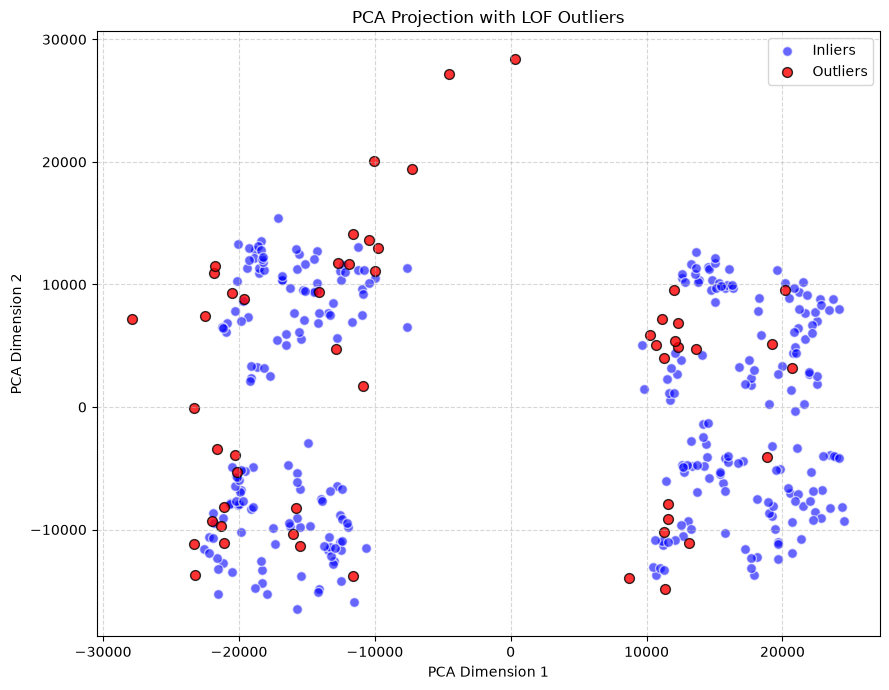

In [41]:
plot_dimesionality_reduction_outliers(pca_scores_final, outlier_indices, inlier_indices, "PCA", "LOF")

In [42]:
print("\n--- IDENTIDADE DOS OUTLIERS DETETADOS ---")

outliers_identificados = results_temp_base.iloc[outlier_indices].copy()

# Mostrar a lista de culpados!
print(f"Encontrados {len(outliers_identificados)} outliers bimanuais:")
print(outliers_identificados[['sub', 'repID', 'movID']].to_string(index=False))


--- IDENTIDADE DOS OUTLIERS DETETADOS ---
Encontrados 52 outliers bimanuais:
 sub  repID  movID
   1      2      2
   1      2      4
   1      2      6
   1      2      8
   1      3      8
   1      4      2
   3      1      2
   3      1      4
   3      1      6
   3      1      8
   3      2      2
   3      2      4
   3      2      6
   3      2      8
   3      3      2
   3      3      4
   3      3      8
   3      4      2
   3      4      4
   3      4      8
   3      5      2
   3      5      6
   3      5      8
   4      1      4
   4      2      4
   4      3      4
   4      4      2
   4      4      4
   4      4      6
   4      5      4
   5      5      2
   6      4      6
   6      5      6
   7      1      2
   7      2      2
   7      4      8
  10      1      2
  10      1      4
  10      1      6
  10      2      8
  10      3      4
  10      4      8
  10      5      8
  11      3      4
  14      1      8
  14      3      2
  14      5      2
  14      

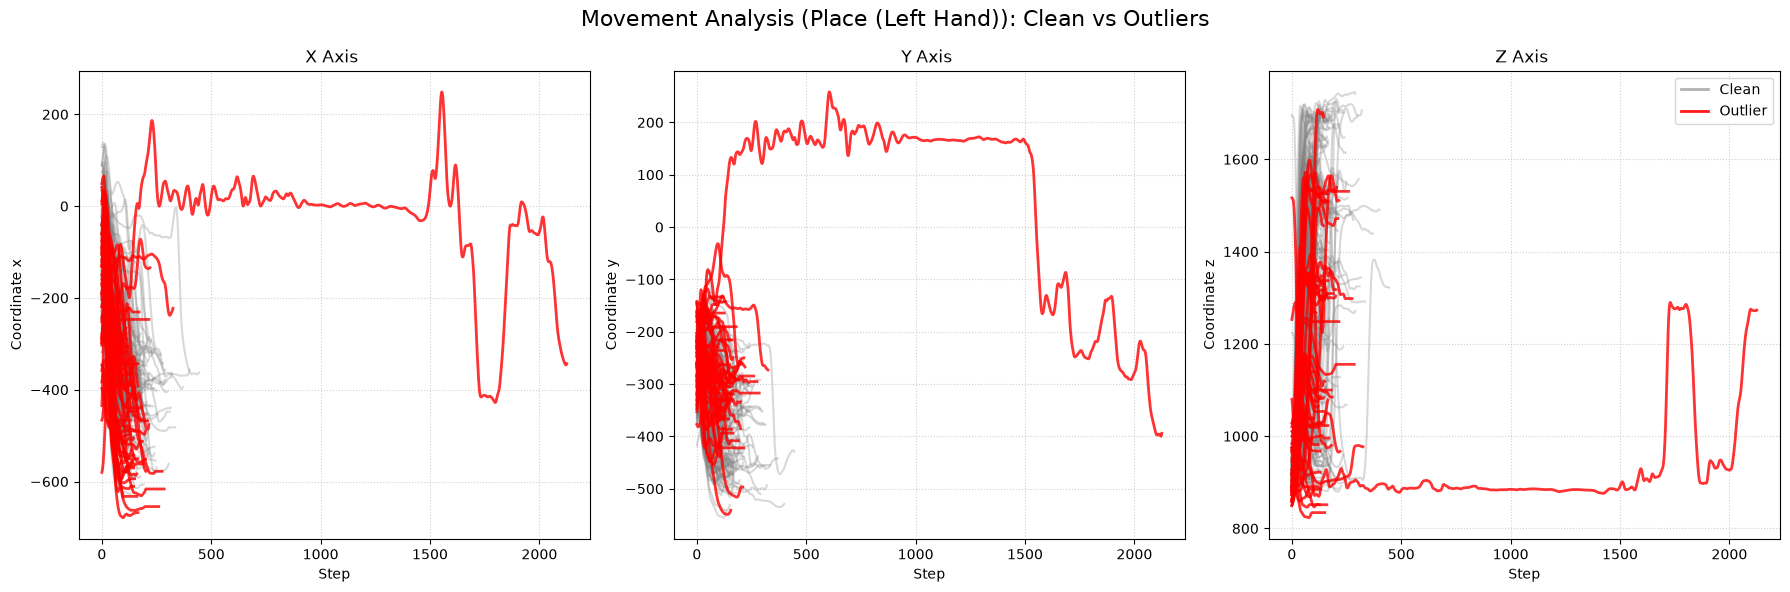

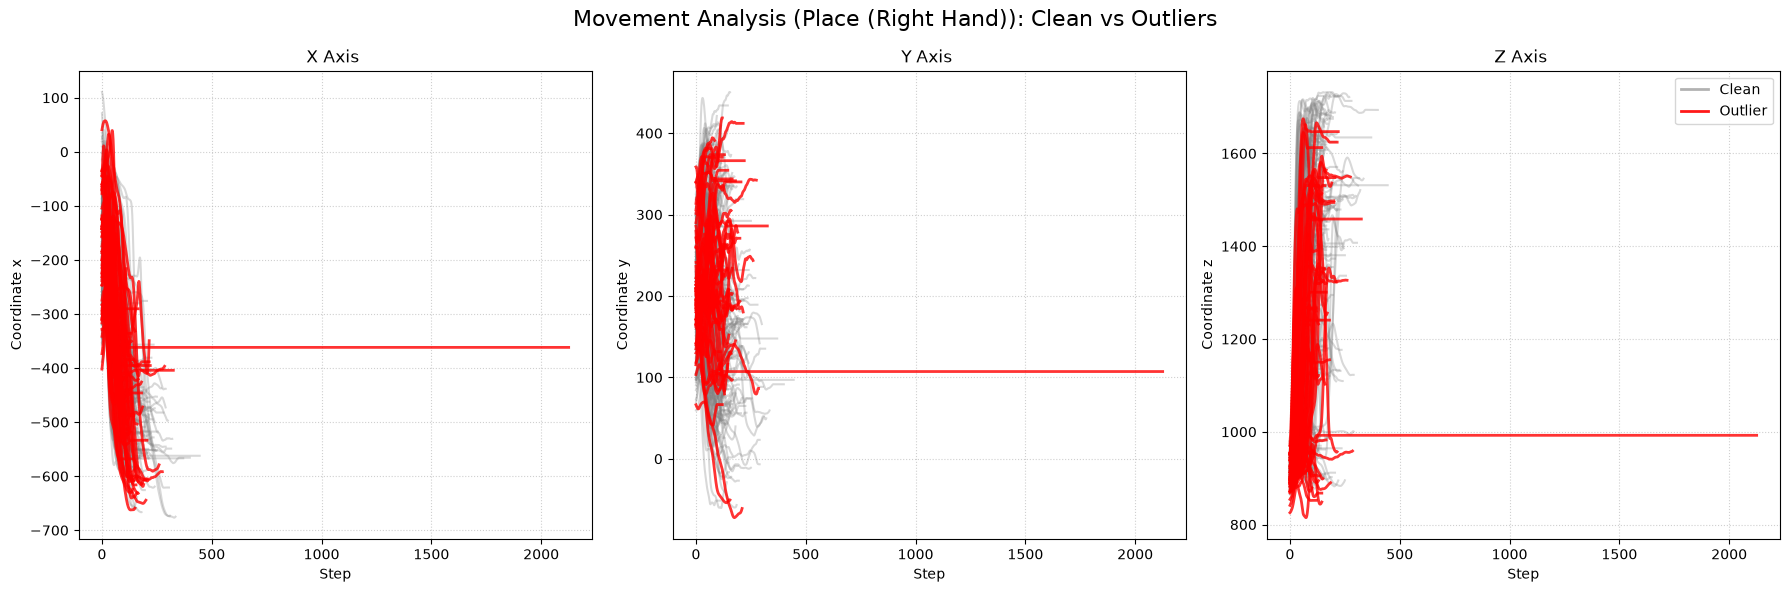

In [43]:
plot_movement_data(
    clean_data=X_movement_clean[:, :, 6:9],       
    outlier_data=X_movement_outliers[:, :, 6:9],  
    target_movement=f"{TARGET_MOVEMENT} (Left Hand)"
)

plot_movement_data(
    clean_data=X_movement_clean[:, :, 15:18],       
    outlier_data=X_movement_outliers[:, :, 15:18],  
    target_movement=f"{TARGET_MOVEMENT} (Right Hand)"
)

In [44]:
# Atualizar também a variável real_outliers_info para o teu script de passar a faca
results_temp = results_temp_base.copy()
results_temp['label'] = final_labels
real_outliers_info = results_temp[results_temp['label'] == -1].copy()

### Exportar Inliers

In [45]:
# ---------------------------------------------------------
# Limpar e isolar APENAS o movimento pretendido
# ---------------------------------------------------------

df_target_only = df[df['movLabel'] == TARGET_MOVEMENT].copy()
outliers_keys = real_outliers_info[['sub', 'repID', 'movID']].copy()

# 2. Fazer um merge (Anti-Join) do dataframe FILTRADO com a lista de outliers do PCA
# O indicator=True cria uma coluna chamada '_merge' que nos diz de onde veio a linha
df_cleaned = pd.merge(df_target_only, outliers_keys, on=['sub', 'repID', 'movID'], how='left', indicator=True)

# 3. Manter APENAS as linhas que estão limpas ('left_only')
df_cleaned = df_cleaned[df_cleaned['_merge'] == 'left_only'].drop(columns=['_merge'])

print(f"--- RESUMO DA LIMPEZA ({TARGET_MOVEMENT}) ---")
print(f"Linhas do movimento {TARGET_MOVEMENT} antes da limpeza: {len(df_target_only)}")
print(f"Linhas removidas (pertencentes a outliers): {len(df_target_only) - len(df_cleaned)}")
print(f"Linhas do movimento {TARGET_MOVEMENT} limpas: {len(df_cleaned)}")

# Para confirmar os movimentos únicos que sobraram do TARGET_MOVEMENT
movimentos_restantes = df_cleaned[['sub', 'repID', 'movID']].drop_duplicates()
n_removidos_esperados = len(outliers_keys)
print(f"\nMovimentos '{TARGET_MOVEMENT}' que SOBRARAM: {len(movimentos_restantes)}")
print(f"Movimentos originais eram {total_trials}, removemos {n_removidos_esperados}, batem certo? {len(movimentos_restantes) == (total_trials - n_removidos_esperados)}")

save_dir = str(Configs.movement_inliers_pca_path(TARGET_MOVEMENT))
df_cleaned.to_csv(save_dir, index=False)

print(f"\n✅ Inliers do {TARGET_MOVEMENT} (via PCA) guardados com sucesso em: {save_dir}")

--- RESUMO DA LIMPEZA (Place) ---
Linhas do movimento Place antes da limpeza: 53215
Linhas removidas (pertencentes a outliers): 10372
Linhas do movimento Place limpas: 42843

Movimentos 'Place' que SOBRARAM: 308
Movimentos originais eram 360, removemos 52, batem certo? True

✅ Inliers do Place (via PCA) guardados com sucesso em: /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/SmartRetail_PCA/data/processed/df_cleaned_inliers_Place_only.csv
